# Simple Classification Model Build Using Machine Learning
**Repository:** [Simple-Classification-Model-ml-intern](https://github.com/dhinesh8023/Simple-Classification-Model-ml-intern)  
**Dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset  
**Environment:** Python 3 & Google Colab  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dhinesh8023/Simple-Classification-Model-ml-intern/blob/main/classification_model.ipynb)
[![Python 3.8+](https://img.shields.io/badge/Python-3.8%2B-blue.svg)](https://www.python.org/)
[![Scikit-Learn](https://img.shields.io/badge/Scikit--Learn-1.2%2B-orange.svg)](https://scikit-learn.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-green.svg)](https://opensource.org/licenses/MIT)

---


## 1. Import Required Libraries

We import essential Python data science packages:
- `numpy` & `pandas`: Data manipulation and numerical operations
- `matplotlib.pyplot` & `seaborn`: Data visualization
- `sklearn`: Dataset loading, preprocessing, model training, and performance metrics


In [1]:
# Step 1: Import required Python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn dataset loader
from sklearn.datasets import load_breast_cancer

# Model selection and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Configure plot aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Load Dataset

We load the dataset directly using Scikit-Learn's built-in `load_breast_cancer()` function and structure the features and target into a Pandas DataFrame.


In [2]:
# Step 2: Load the Breast Cancer Wisconsin dataset
cancer_data = load_breast_cancer()

# Construct DataFrame for features
X_raw = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)

# Construct Series for target labels
y_raw = pd.Series(cancer_data.target, name="target")

# Display basic dataset dimensions
print(f"Dataset Dimensions: {X_raw.shape[0]} rows (samples) and {X_raw.shape[1]} columns (features)")
print(f"Target Class Mapping: {cancer_data.target_names}")
print(f"   -> 0: {cancer_data.target_names[0]} (cancerous)")
print(f"   -> 1: {cancer_data.target_names[1]} (non-cancerous)")


Dataset Dimensions: 569 rows (samples) and 30 columns (features)
Target Class Mapping: ['malignant' 'benign']
   -> 0: malignant (cancerous)
   -> 1: benign (non-cancerous)


## 3. Exploratory Data Analysis (EDA)

Before building predictive models, we examine data completeness, feature summaries, and the balance of target classes.


In [3]:
# Display the first 5 rows of the feature dataset
print("First 5 rows of feature attributes:")
X_raw.head()


First 5 rows of feature attributes:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Check for missing values across all columns
missing_values_count = X_raw.isnull().sum().sum()
print(f"Total Missing Values in Dataset: {missing_values_count}")

# Check data types and memory usage
print("\nDataset Info:")
X_raw.info()


Total Missing Values in Dataset: 0

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 n

Target Class Distribution:
        Class  Sample Count  Percentage (%)
   benign (1)           357           62.74
malignant (0)           212           37.26


/tmp/ipykernel_1877/1877278969.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=dist_df["Class"], y=dist_df["Sample Count"], palette=["#2a9d8f", "#e76f51"])


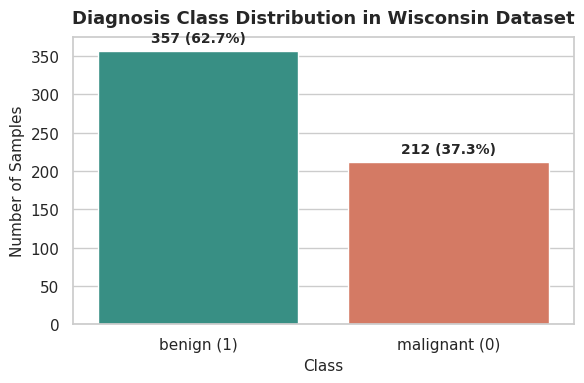

In [5]:
# Examine target class distribution
class_counts = y_raw.value_counts()
class_percentages = (y_raw.value_counts(normalize=True) * 100).round(2)

dist_df = pd.DataFrame({
    "Class": [f"{cancer_data.target_names[i]} ({i})" for i in class_counts.index],
    "Sample Count": class_counts.values,
    "Percentage (%)": class_percentages.values
})
print("Target Class Distribution:")
print(dist_df.to_string(index=False))

# Plot target class distribution
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=dist_df["Class"], y=dist_df["Sample Count"], palette=["#2a9d8f", "#e76f51"])
plt.title("Diagnosis Class Distribution in Wisconsin Dataset", fontsize=13, fontweight="bold", pad=10)
plt.ylabel("Number of Samples", fontsize=11)
plt.xlabel("Class", fontsize=11)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(y_raw)*100:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                textcoords='offset points')

plt.tight_layout()
plt.show()


## 4. Data Preprocessing

Data preprocessing is essential to ensure that models train efficiently and without numerical bias:
1. **Feature-Target Separation:** Isolate input variables $X$ from response label $y$.
2. **Feature Scaling:** Apply `StandardScaler` to transform features such that $\mu = 0$ and $\sigma = 1$:
   $$z = \frac{x - \mu}{\sigma}$$
   
> **Why Scale Features?**
> - **Logistic Regression** uses gradient-based optimization and $L_2$ regularization. Unscaled features with large ranges (e.g., `mean area` $\approx 1000$) would disproportionately dominate features with small numerical ranges (e.g., `mean smoothness` $\approx 0.1$), causing slow convergence and biased parameter penalties.
> - **Decision Trees** are non-parametric and split based on ordinal thresholds along single dimensions, making them inherently scale-invariant.


In [6]:
# Feature and Target assignment
X = X_raw.copy()
y = y_raw.copy()

print(f"Features matrix shape: {X.shape}")
print(f"Target vector shape:   {y.shape}")


Features matrix shape: (569, 30)
Target vector shape:   (569,)


## 5. Train-Test Split

We partition our dataset into **80% training data** (used to teach our models) and **20% testing data** (held out to evaluate generalizability).

We fix `random_state=42` to guarantee complete reproducibility.


In [7]:
# Split the dataset: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

# Initialize and apply StandardScaler
scaler = StandardScaler()

# Fit scaler exclusively on training data to prevent data leakage, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling applied successfully!")
print(f"Training mean (first feature after scaling): {X_train_scaled[:, 0].mean():.4f}")
print(f"Training std (first feature after scaling):  {X_train_scaled[:, 0].std():.4f}")


Training set: 455 samples (80.0%)
Testing set:  114 samples (20.0%)

Feature scaling applied successfully!
Training mean (first feature after scaling): -0.0000
Training std (first feature after scaling):  1.0000


## 6. Model 1: Logistic Regression

**Logistic Regression** models the probability that an observation belongs to a given category using the logistic (sigmoid) function:
$$P(y=1|X) = \sigma(w^T X + b) = \frac{1}{1 + e^{-(w^T X + b)}}$$

- **Type:** Linear, Parametric Classifier
- **Strengths:** Fast, highly interpretable, provides calibrated probability scores, less prone to overfitting on small datasets when regularized.
- **Assumptions:** Assumes a linear relationship between input features and the log-odds of the outcome.


In [8]:
# Initialize Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)

# Train model on standardized training features
log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print(f"Number of iterations required: {log_reg.n_iter_[0]}")


Logistic Regression model trained successfully!
Number of iterations required: 20


## 7. Model 2: Decision Tree Classifier


In [9]:
# Initialize Decision Tree model with regularization to prevent overfitting
dt_classifier = DecisionTreeClassifier(random_state=42, max_depth=4)

# Train model on training features (raw feature values are suitable due to scale invariance)
dt_classifier.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully!")
print(f"Tree depth: {dt_classifier.get_depth()}")
print(f"Number of leaves: {dt_classifier.get_n_leaves()}")


Decision Tree Classifier trained successfully!
Tree depth: 4
Number of leaves: 12


## 8. Model Predictions


In [10]:
# Generate predictions for both models on the test set
y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_dt = dt_classifier.predict(X_test)

# Display sample of first 10 predictions alongside actual targets
pred_comparison = pd.DataFrame({
    "Actual Label": [cancer_data.target_names[val] for val in y_test.iloc[:10]],
    "Logistic Reg Pred": [cancer_data.target_names[val] for val in y_pred_lr[:10]],
    "Decision Tree Pred": [cancer_data.target_names[val] for val in y_pred_dt[:10]]
})
print("First 10 Predictions Comparison:")
pred_comparison


First 10 Predictions Comparison:


,Actual Label,Logistic Reg Pred,Decision Tree Pred
0,benign,benign,benign
1,malignant,malignant,malignant
2,malignant,malignant,malignant
3,benign,benign,benign
4,benign,benign,benign
5,malignant,malignant,malignant
6,malignant,malignant,malignant
7,malignant,malignant,malignant
8,benign,benign,malignant
9,benign,benign,benign


## 9. Model Evaluation


In [11]:
# Compute evaluation metrics for Logistic Regression
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("=" * 55)
print("     LOGISTIC REGRESSION PERFORMANCE METRICS")
print("=" * 55)
print(f"Accuracy Score:  {acc_lr:.4f}  ({acc_lr*100:.2f}%)")
print(f"Precision Score: {prec_lr:.4f}  ({prec_lr*100:.2f}%)")
print(f"Recall Score:    {rec_lr:.4f}  ({rec_lr*100:.2f}%)")
print("\nConfusion Matrix:")
print(cm_lr)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=cancer_data.target_names))


     LOGISTIC REGRESSION PERFORMANCE METRICS
Accuracy Score:  0.9737  (97.37%)
Precision Score: 0.9722  (97.22%)
Recall Score:    0.9859  (98.59%)

Confusion Matrix:
[[41  2]
 [ 1 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [12]:
# Compute evaluation metrics for Decision Tree Classifier
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("=" * 55)
print("     DECISION TREE CLASSIFIER PERFORMANCE METRICS")
print("=" * 55)
print(f"Accuracy Score:  {acc_dt:.4f}  ({acc_dt*100:.2f}%)")
print(f"Precision Score: {prec_dt:.4f}  ({prec_dt*100:.2f}%)")
print(f"Recall Score:    {rec_dt:.4f}  ({rec_dt*100:.2f}%)")
print("\nConfusion Matrix:")
print(cm_dt)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=cancer_data.target_names))


     DECISION TREE CLASSIFIER PERFORMANCE METRICS
Accuracy Score:  0.9474  (94.74%)
Precision Score: 0.9577  (95.77%)
Recall Score:    0.9577  (95.77%)

Confusion Matrix:
[[40  3]
 [ 3 68]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



## 10. Confusion Matrix Visualization

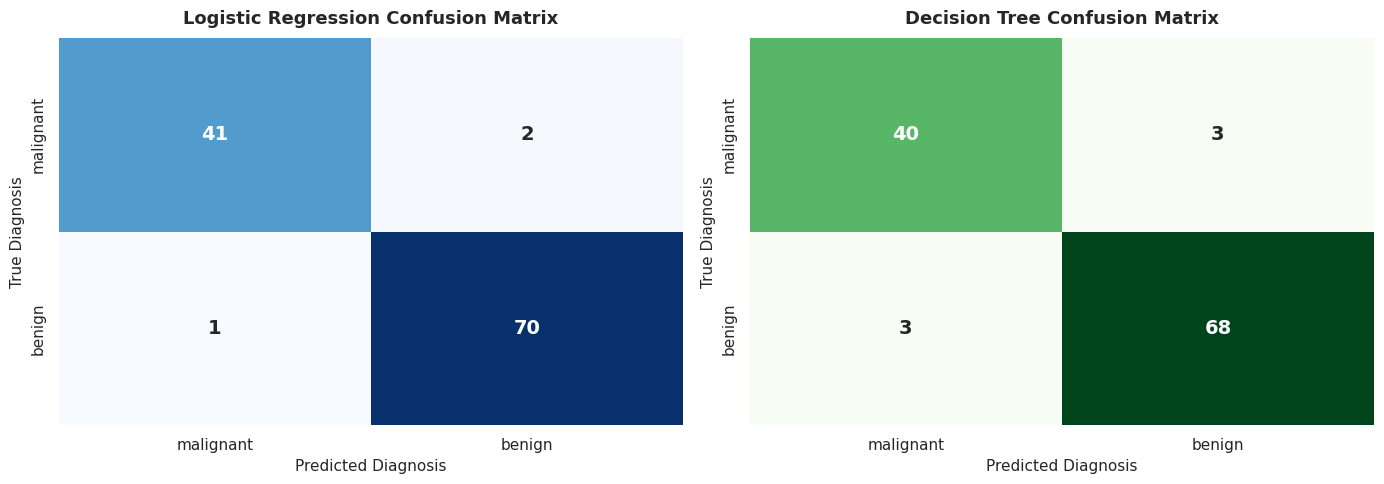

In [13]:
# Plot Confusion Matrix Heatmaps side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Heatmap
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    annot_kws={"size": 14, "weight": "bold"},
    xticklabels=cancer_data.target_names,
    yticklabels=cancer_data.target_names
)
axes[0].set_title("Logistic Regression Confusion Matrix", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Predicted Diagnosis", fontsize=11)
axes[0].set_ylabel("True Diagnosis", fontsize=11)

# Decision Tree Heatmap
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    annot_kws={"size": 14, "weight": "bold"},
    xticklabels=cancer_data.target_names,
    yticklabels=cancer_data.target_names
)
axes[1].set_title("Decision Tree Confusion Matrix", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("Predicted Diagnosis", fontsize=11)
axes[1].set_ylabel("True Diagnosis", fontsize=11)

plt.tight_layout()
plt.show()


## 11. Model Performance Comparison



In [14]:
# Create summary comparison DataFrame
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall"],
    "Logistic Regression": [f"{acc_lr*100:.2f}%", f"{prec_lr*100:.2f}%", f"{rec_lr*100:.2f}%"],
    "Decision Tree": [f"{acc_dt*100:.2f}%", f"{prec_dt*100:.2f}%", f"{rec_dt*100:.2f}%"]
})

print("=" * 55)
print("            MODEL PERFORMANCE COMPARISON TABLE")
print("=" * 55)
print(comparison_df.to_string(index=False))


            MODEL PERFORMANCE COMPARISON TABLE
   Metric Logistic Regression Decision Tree
 Accuracy              97.37%        94.74%
Precision              97.22%        95.77%
   Recall              98.59%        95.77%


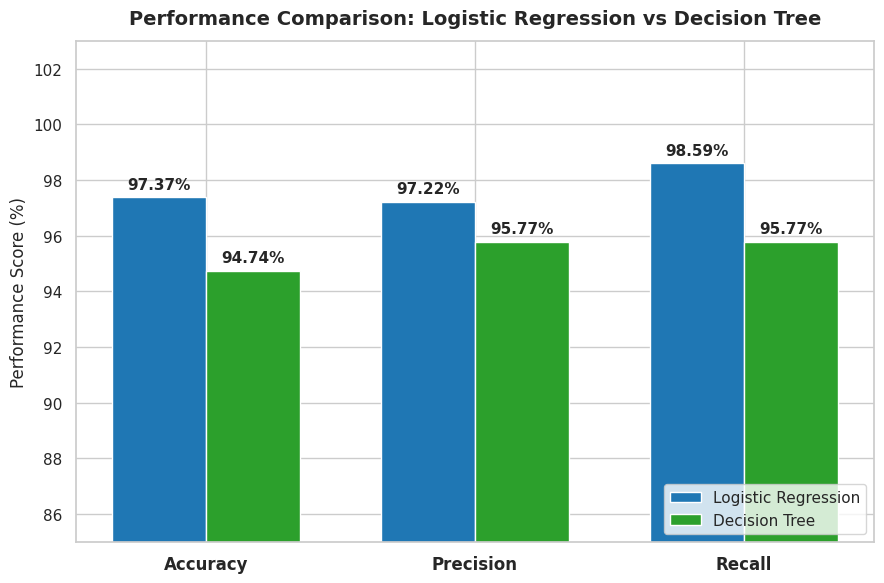

In [15]:
# Generate Comparative Bar Chart for Accuracy, Precision, and Recall
metrics_labels = ["Accuracy", "Precision", "Recall"]
lr_values = [acc_lr * 100, prec_lr * 100, rec_lr * 100]
dt_values = [acc_dt * 100, prec_dt * 100, rec_dt * 100]

x = np.arange(len(metrics_labels))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

rects1 = ax.bar(x - bar_width/2, lr_values, bar_width, label="Logistic Regression", color="#1f77b4")
rects2 = ax.bar(x + bar_width/2, dt_values, bar_width, label="Decision Tree", color="#2ca02c")

ax.set_ylabel("Performance Score (%)", fontsize=12)
ax.set_title("Performance Comparison: Logistic Regression vs Decision Tree", fontsize=14, fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics_labels, fontsize=12, fontweight="bold")
ax.set_ylim(85, 103)
ax.legend(frameon=True, loc="lower right", fontsize=11)

# Annotate bars with exact percentages
def add_bar_labels(rects):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.2f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

add_bar_labels(rects1)
add_bar_labels(rects2)

plt.tight_layout()
plt.show()
